In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [ ]:
# Project Scope: National Park Biodiversity and Conservation Analysis

## Project Aim

The aim of this project is to use data analysis and statistical methods to investigate biodiversity, species conservation status and wildlife observations across four national parks.

A further objective is to understand how statistical methods, including sample-size determination, can be applied to a foot-and-mouth disease study.

## Project Objectives

1. Investigate the variety of species recorded across the national parks.
2. Examine the conservation status of different species.
3. Identify whether conservation status is associated with species category.
4. Compare wildlife observations across the four national parks.
5. Investigate the sample-size requirements for a foot-and-mouth disease study.
6. Use statistical findings to develop evidence-based recommendations.

## Key Research Questions

- Which species categories have the greatest number of species requiring conservation attention?
- Is there a statistically significant relationship between species category and conservation status?
- Which species are most frequently observed in each national park?
- How can an appropriate sample size be determined for a foot-and-mouth disease study?

## Expected Outcomes

The project aims to identify patterns in biodiversity, understand conservation concerns and demonstrate how statistical analysis can support informed decision-making in wildlife conservation and animal disease research.

In [ ]:
# Data Collection and Sources

## Biodiversity Data

Two CSV datasets were provided for the project.

**1. species_info.csv**

This dataset contains:
- Category of species
- Scientific name
- Common name
- Conservation status

**2. observations.csv**

This dataset contains:
- Scientific name
- National park
- Number of observations

## Data Preparation

The datasets will be imported into Python using the Pandas library.

The data will be examined for:
- Missing values
- Duplicate records
- Incorrect data types
- Inconsistent species names

The two datasets will then be combined using the scientific_name column to support further analysis.

## Foot-and-Mouth Disease Data

A separate dataset or study document is required for the foot-and-mouth disease investigation.

The information needed will depend on the research objective and may include:
- Target livestock population
- Expected disease prevalence
- Previous disease prevalence estimates
- Desired confidence level
- Acceptable margin of error

The relevant study information must be identified before calculating the required sample size.

## Data Limitations

The two biodiversity datasets do not contain livestock disease information. Therefore, they cannot be used to calculate foot-and-mouth disease prevalence or determine the appropriate sample size for that study.

In [2]:
species = pd.read_csv('species_info.csv')
observations = pd.read_csv('observations.csv')

In [3]:
display(species.head())
display(observations.head())

,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


In [4]:
print(species.info())
print(observations.info())

print(species.describe(include='all'))
print(observations.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23296 non-null  object
 1   park_name        23296 non-null  object
 2   observations     23296 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 546.1+ KB
None
              category    scientific_name        common_names  \
count             5824               5824                5824   
unique               7           

In [5]:
print(species.isnull().sum())
print(observations.isnull().sum())

category                  0
scientific_name           0
common_names              0
conservation_status    5633
dtype: int64
scientific_name    0
park_name          0
observations       0
dtype: int64


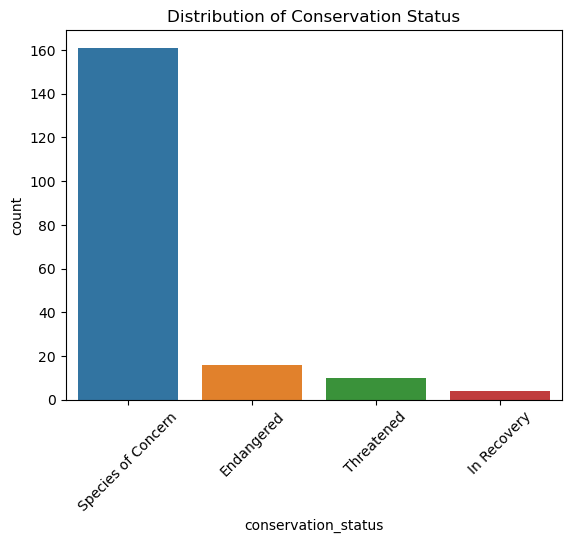

In [6]:
sns.countplot(data=species, x='conservation_status',
              order=species['conservation_status'].value_counts().index)

plt.title('Distribution of Conservation Status')
plt.xticks(rotation=45)
plt.show()

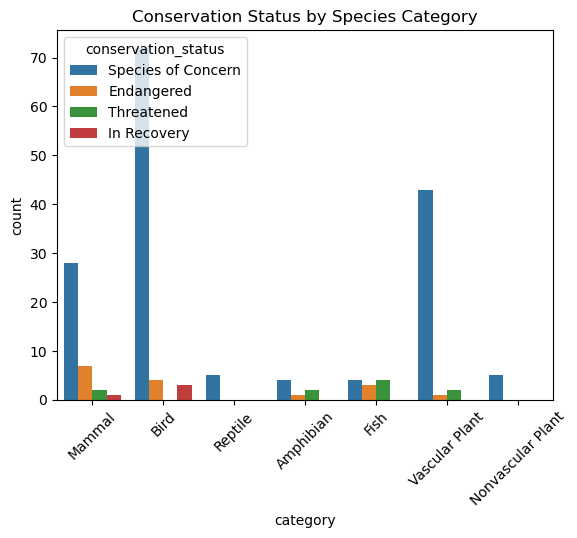

In [7]:
sns.countplot(data=species, x='category',
              hue='conservation_status')

plt.title('Conservation Status by Species Category')
plt.xticks(rotation=45)
plt.show()

In [8]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    species['category'],
    species['conservation_status']
)

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("P-value:", p)

if p < 0.05:
    print("There is a statistically significant association.")
else:
    print("There is no statistically significant association.")

Chi-square statistic: 53.91636314015659
P-value: 1.8909788349761653e-05
There is a statistically significant association.


In [9]:
merged_data = pd.merge(species, observations, on='scientific_name')

park_species = merged_data.groupby(
    ['park_name', 'common_names']
)['observations'].sum().reset_index()

In [10]:
top_species = park_species.loc[
    park_species.groupby('park_name')['observations'].idxmax()
]

display(top_species)

,park_name,common_names,observations
1729,Bryce National Park,Dicranum Moss,707
7233,Great Smoky Mountains National Park,Dicranum Moss,544
12737,Yellowstone National Park,Dicranum Moss,1779
17283,Yosemite National Park,Brachythecium Moss,1066


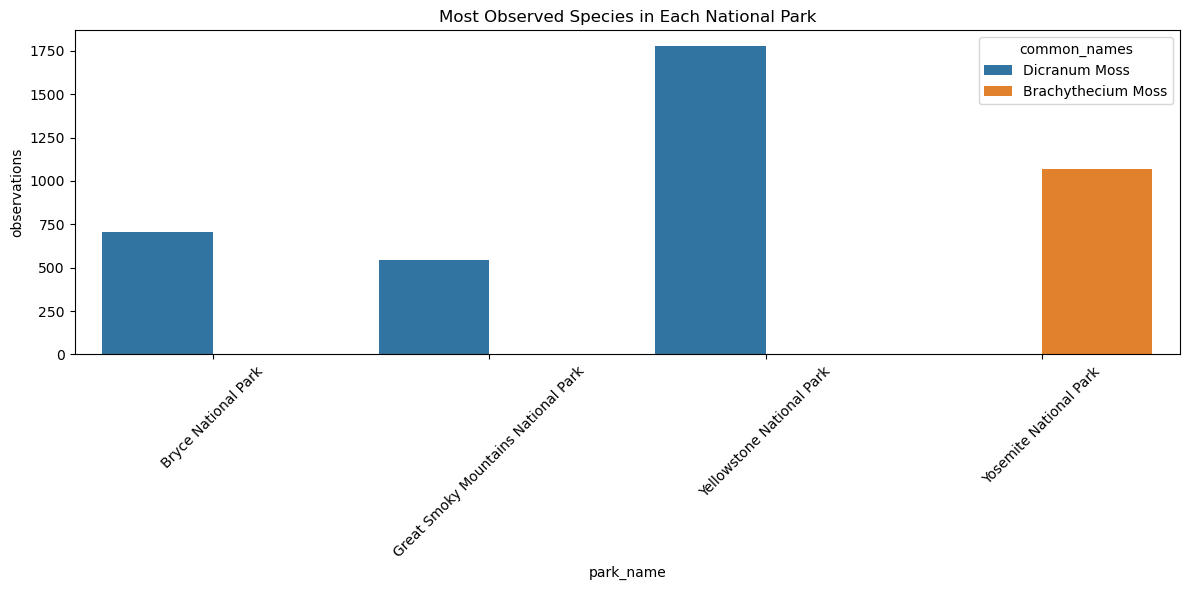

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(data=top_species,
            x='park_name',
            y='observations',
            hue='common_names')

plt.title('Most Observed Species in Each National Park')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
## Analysis of National Park Biodiversity Data
1. Data Overview
The project uses two datasets: species_info.csv and observations.csv.

The species dataset contains 5,824 records and 4 columns, providing information about species categories, scientific names, common names and conservation statuses.

The observations dataset contains 23,296 records and 3 columns, recording species sightings across four national parks.

The summary statistics show that:
- There are 7 different species categories.
- There are 5,541 unique scientific names.
- The average number of observations per record is approximately 142.
- The highest number of observations in a single record is 321.
2. Missing Values Analysis
The missing value analysis identified:
- The species dataset has 5,633 missing values in the conservation_status column.
- The observations dataset contains no missing values.
This indicates that most species do not have a recorded conservation status in the dataset. These missing values should not automatically be treated as endangered species.

The most frequent recorded conservation status is Species of Concern, appearing 161 times among the 191 records with a conservation status.
3. Distribution of Conservation Status
The first visualisation examines the distribution of species across different conservation categories.

The analysis shows that Species of Concern is the most frequently recorded conservation status. Other conservation categories are less frequently represented.

This suggests that although many species have no recorded conservation status, some species have been identified as requiring conservation attention.
4. Conservation Status by Species Category
The second visualisation compares conservation statuses across different species categories, including mammals, birds, fish, reptiles, amphibians, nonvascular plants and vascular plants.

This comparison helps identify whether certain groups have more species recorded under threatened conservation categories.

The results highlight the importance of examining conservation status across different biological groups rather than treating all species equally.
5. Statistical Significance Analysis
A Chi-square test was conducted to investigate whether there is an association between species category and conservation status.

The results were:
Statistical measure	Result
Chi-square statistic	53.9164
P-value	0.00001891
Significance level	0.05

Interpretation:

Since the p-value is smaller than 0.05, there is a statistically significant association between species category and conservation status.

This suggests that conservation status varies across different species categories. However, the result does not establish that species category causes a particular conservation status.
6. Most Observed Species in Each National Park
The species and observations datasets were merged using the scientific_name column.

The analysis identified the most frequently observed species in each national park.

The results were:
National Park	Most observed species	Observations
Bryce National Park	Dicranum Moss	707
Great Smoky Mountains	Dicranum Moss	544
Yellowstone National Park	Dicranum Moss	1,779
Yosemite National Park	Brachythecium Moss	1,066

Interpretation:

Dicranum Moss was the most frequently observed species in three of the four national parks. Brachythecium Moss was the most frequently observed in Yosemite National Park.

Yellowstone National Park recorded the highest number of observations for its most frequently observed species, with 1,779 observations.

These findings demonstrate differences in recorded species observations across the national parks.
7. Overall Conclusion
Conclusion
The exploratory data analysis revealed interesting patterns in wildlife conservation across four national parks. The analysis identified Species of Concern as the most frequently recorded conservation status and demonstrated a statistically significant association between species category and conservation status.

The observations analysis also showed that Dicranum Moss was the most frequently observed species in three national parks, while Brachythecium Moss was most common in Yosemite National Park.

Overall, this project highlights the importance of monitoring biodiversity and understanding conservation patterns. The findings provide useful insights into species distribution and conservation statuses, supporting the importance of protecting wildlife and maintaining biodiversity across national parks.

In [ ]:
# Conclusion – National Park Biodiversity Analysis

## 1. What I Learned Throughout the Process 
Throughout this project, I developed my understanding of how Python can be used to explore, analyse and interpret biodiversity data.

I gained practical experience using the Pandas library to import, organise, clean and investigate datasets. I learned how to identify missing values, examine different species categories and combine datasets using scientific names.

I also developed my skills in data visualisation and statistical analysis. In particular, carrying out a Chi-square test helped me understand how statistical methods can be used to investigate relationships between variables and determine whether observed patterns are statistically significant.

This project improved my confidence in using Jupyter Notebook to conduct data analysis and communicate findings through graphs, calculations and written explanations.

## 2. Were the Results What I Expected?

The results revealed some interesting patterns that I had not necessarily expected.

One notable finding was that most species records did not have a recorded conservation status. Of the 5,824 records in the species dataset, 5,633 had missing conservation-status values.

Among the records with a conservation status, Species of Concern was the most frequently recorded category.

The Chi-square test also produced a statistically significant result, with a p-value of approximately 0.00001891. This indicated an association between species category and conservation status.

Another interesting finding was that Dicranum Moss was the most frequently observed species in three of the four national parks, while Brachythecium Moss was the most frequently observed in Yosemite National Park.

These findings demonstrated that analysing data can reveal patterns that may not be immediately obvious.

## 3. Key Findings and Takeaways

The main findings from the project were:

- The species dataset contained 5,824 records, while the observations dataset contained 23,296 records.
- There were 7 different species categories.
- Species of Concern was the most frequently recorded conservation status.
- The Chi-square test identified a statistically significant association between species category and conservation status.
- Dicranum Moss was the most frequently observed species in Bryce National Park, Great Smoky Mountains and Yellowstone National Park.
- Brachythecium Moss was the most frequently observed species in Yosemite National Park.

## 4. Overall Conclusion

Overall, this project demonstrated how data analysis can help us understand biodiversity and conservation patterns across national parks.

By using Python, Pandas, data visualisation and statistical testing, I was able to identify differences in conservation status between species categories and explore wildlife observation patterns across four national parks.

One of the most important lessons was that data analysis involves more than producing graphs and calculations. It also requires understanding the quality of the data, interpreting statistical results correctly and recognising the limitations of the information available.

The findings highlight the importance of continued biodiversity monitoring and conservation efforts. They also demonstrate how data-driven insights can support better understanding and decision-making in wildlife conservation.

This project has strengthened my practical data science skills and given me valuable experience in applying statistical techniques to a real-world environmental research topic.